# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 01: Exploratory Data Analysis (EDA)
**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.

---

All analysis in this notebook uses the training set only (`data/train_clean.csv`, written by Notebook 00). The locked test set is never read here.

## 1. Environment Setup and Data Ingestion
*Code: Generated by AI Assistant*


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Ensure local source modules can be imported
sys.path.append(os.path.abspath('..'))
from src.data_utils import load_train, add_readable_units

# Styling and visualization configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

figures_dir = os.path.join('..', 'figures')
os.makedirs(figures_dir, exist_ok=True)

# Load the training set only (written by Notebook 00)
train_raw = load_train()
print(f"Training set loaded: {train_raw.shape[0]:,} rows, {train_raw.shape[1]} columns | Range: {train_raw['dteday'].min().date()} to {train_raw['dteday'].max().date()}")

# Add un-normalized variables for intuitive interpretation
train_df = add_readable_units(train_raw)
train_df.head()

Training set loaded: 15,643 rows, 17 columns | Range: 2011-01-01 to 2012-10-18


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,atemp,hum,windspeed,casual,registered,cnt,temp_c,atemp_c,hum_pct,windspeed_kmh
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,0.2879,0.81,0.0,3,13,16,9.84,14.395,81.0,0.0
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,0.2727,0.80,0.0,8,32,40,9.02,13.635,80.0,0.0
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,0.2727,0.80,0.0,5,27,32,9.02,13.635,80.0,0.0
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,0.2879,0.75,0.0,3,10,13,9.84,14.395,75.0,0.0
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,0.2879,0.75,0.0,0,1,1,9.84,14.395,75.0,0.0


---
## 2. Data Quality Audit
*Code: Generated by AI Assistant*

Data quality checks on the training set:
- Verification of rows, columns, and data types
- Missing-value markers (nulls, `NaN`, placeholder strings)
- Duplicate records
- Integrity check: $\text{casual} + \text{registered} == \text{cnt}$
- Timestamp coverage (missing hours)

In [2]:
# 1. Dataset Dimensions & Column Types
print("--- Data Schema & Non-Null Counts ---")
train_raw.info()

# 2. Missing Value & Anomaly Scan
print("\n--- Missing Value Count per Feature ---")
missing_counts = train_raw.isnull().sum()
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "Zero missing values detected across all columns.")

# Check for placeholder string missing values in object columns
for col in train_raw.select_dtypes(include='object').columns:
    q_count = (train_raw[col] == '?').sum()
    if q_count > 0:
        print(f"Placeholder '?' detected in {col}: {q_count} rows")

# 3. Duplicate Rows
duplicates = train_raw.duplicated().sum()
print(f"\nDuplicate rows detected: {duplicates}")

# 4. Target Identity Verification (casual + registered == cnt)
component_sum = train_raw['casual'] + train_raw['registered']
discrepancies = (component_sum != train_raw['cnt']).sum()
print(f"Discrepancies in (casual + registered == cnt): {discrepancies}")
assert discrepancies == 0, 'Target variable cnt does not match sum of casual + registered!'


--- Data Schema & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15643 entries, 0 to 15642
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     15643 non-null  int64         
 1   dteday      15643 non-null  datetime64[ns]
 2   season      15643 non-null  int64         
 3   yr          15643 non-null  int64         
 4   mnth        15643 non-null  int64         
 5   hr          15643 non-null  int64         
 6   holiday     15643 non-null  int64         
 7   weekday     15643 non-null  int64         
 8   workingday  15643 non-null  int64         
 9   weathersit  15643 non-null  int64         
 10  temp        15643 non-null  float64       
 11  atemp       15643 non-null  float64       
 12  hum         15643 non-null  float64       
 13  windspeed   15643 non-null  float64       
 14  casual      15643 non-null  int64         
 15  registered  15643 non-null  int6

### Data Inspection Notes
**Author**: Kok Wai Ying
<!-- Add your observations on data structure, row counts, missingness, and variable types here -->
The training set contains 15,643 rows and 17 columns. No missing values to correct for. 

The target variable is: cnt 

While all variables are stored numerically (int64/float64), they fall into three distinct types for pipeline design:

1. True continuous: temp, atemp,hum,windspeed
2. Categorical Codes: season, mnth,hr, weekday, weathersit. These are non-linear and must be one-hot encoded in the pipeline.
3. Binary Flags: holiday,workingday,yr

Special Note: dteday is a datetime object (used only for tracking and EDA)

In [3]:
# 5. Timestamp Continuity & Range
date_min, date_max = train_raw['dteday'].min(), train_raw['dteday'].max()
total_days = (date_max - date_min).days + 1

print(f"Date range: {date_min.strftime('%Y-%m-%d')} to {date_max.strftime('%Y-%m-%d')} ({total_days} total calendar days)")
print(f"Total hours recorded: {len(train_raw):,} out of potential {total_days * 24:,} hours ({(len(train_raw)/(total_days * 24))*100:.2f}% coverage)")


Date range: 2011-01-01 to 2012-10-18 (657 total calendar days)
Total hours recorded: 15,643 out of potential 15,768 hours (99.21% coverage)


In [4]:
# 6.Find exactly which hours are missing
# Create a perfect timeline from min date to max date
expected_hours = pd.date_range(start=date_min, end=date_max, freq='h')

# Create the actual timeline in the dataframe
actual_hours = pd.to_datetime(train_raw['dteday']) + pd.to_timedelta(train_raw['hr'], unit='h')

# Find the difference
missing_hours = expected_hours.difference(actual_hours)

print(f"Total missing hours: {len(missing_hours)}")
if len(missing_hours) > 0:
    print("First 10 missing hours:")
    print(missing_hours[:10])
    print("\nLast 10 missing hours:")
    print(missing_hours[-10:])

Total missing hours: 125
First 10 missing hours:
DatetimeIndex(['2011-01-02 05:00:00', '2011-01-03 02:00:00',
               '2011-01-03 03:00:00', '2011-01-04 03:00:00',
               '2011-01-05 03:00:00', '2011-01-06 03:00:00',
               '2011-01-07 03:00:00', '2011-01-11 03:00:00',
               '2011-01-11 04:00:00', '2011-01-12 03:00:00'],
              dtype='datetime64[ns]', freq=None)

Last 10 missing hours:
DatetimeIndex(['2012-01-02 03:00:00', '2012-01-10 03:00:00',
               '2012-01-17 03:00:00', '2012-02-06 03:00:00',
               '2012-02-20 04:00:00', '2012-02-21 03:00:00',
               '2012-02-29 04:00:00', '2012-03-11 02:00:00',
               '2012-04-02 03:00:00', '2012-04-11 04:00:00'],
              dtype='datetime64[ns]', freq=None)


### Interpretation for Missing Data

**Author**: Kok Wai Ying

We identified 125 missing hours in the training set (99.21% coverage). Upon investigating the specific timestamps, we found these gaps are scattered randomly across the two years and are almost exclusively isolated to the 2:00 AM - 5:00 AM window.

These missing records are highly likely due to Daylight Saving Time shifts or scheduled overnight system maintenance/downtime. Because these gaps occur during the "Dead Zone" where bike demand is virtually zero, they have no statistically meaningful impact on the target variable.

Pipeline Decision: We will not impute these missing hours. The chronological order of the remaining rows is sufficient for TimeSeriesSplit. The model will simply treat the subsequent hour as the next time-step.



---
## 3. Question 1: What is the Overall Trend of Bike Rental Usage?
*Code: Generated by AI Assistant*


In [5]:
# Daily aggregate trend across the training period (2011-01-01 to 2012-10-18)
daily_trend = train_df.groupby('dteday').agg({
    'cnt': 'sum',
    'casual': 'sum',
    'registered': 'sum',
    'temp_c': 'mean'
}).reset_index()

daily_trend['cnt_7d_mavg'] = daily_trend['cnt'].rolling(window=7, center=True).mean()
daily_trend['cnt_30d_mavg'] = daily_trend['cnt'].rolling(window=30, center=True).mean()

# Year-over-year growth summary on matching months (Jan - Sep), since late 2012 is held out
same_period = train_df[train_df['mnth'] <= 9]
tot_2011 = same_period[same_period['yr'] == 0]['cnt'].sum()
tot_2012 = same_period[same_period['yr'] == 1]['cnt'].sum()
mean_hr_2011 = same_period[same_period['yr'] == 0]['cnt'].mean()
mean_hr_2012 = same_period[same_period['yr'] == 1]['cnt'].mean()
growth_rate = ((tot_2012 - tot_2011) / tot_2011) * 100

print(f"Jan-Sep 2011 Total Rentals: {tot_2011:,} (Mean: {mean_hr_2011:.1f} rentals/hour)")
print(f"Jan-Sep 2012 Total Rentals: {tot_2012:,} (Mean: {mean_hr_2012:.1f} rentals/hour)")
print(f"Year-over-Year Growth Rate (Jan-Sep): {growth_rate:.2f}%")

Jan-Sep 2011 Total Rentals: 930,102 (Mean: 144.4 rentals/hour)
Jan-Sep 2012 Total Rentals: 1,574,358 (Mean: 239.8 rentals/hour)
Year-over-Year Growth Rate (Jan-Sep): 69.27%


### Interpretation:
**Author**: Lee Sin Yang

Year over year growth is present at about 69.27% higher in 2012. Year must thus be accounted for, or some data engineering will need to be done.

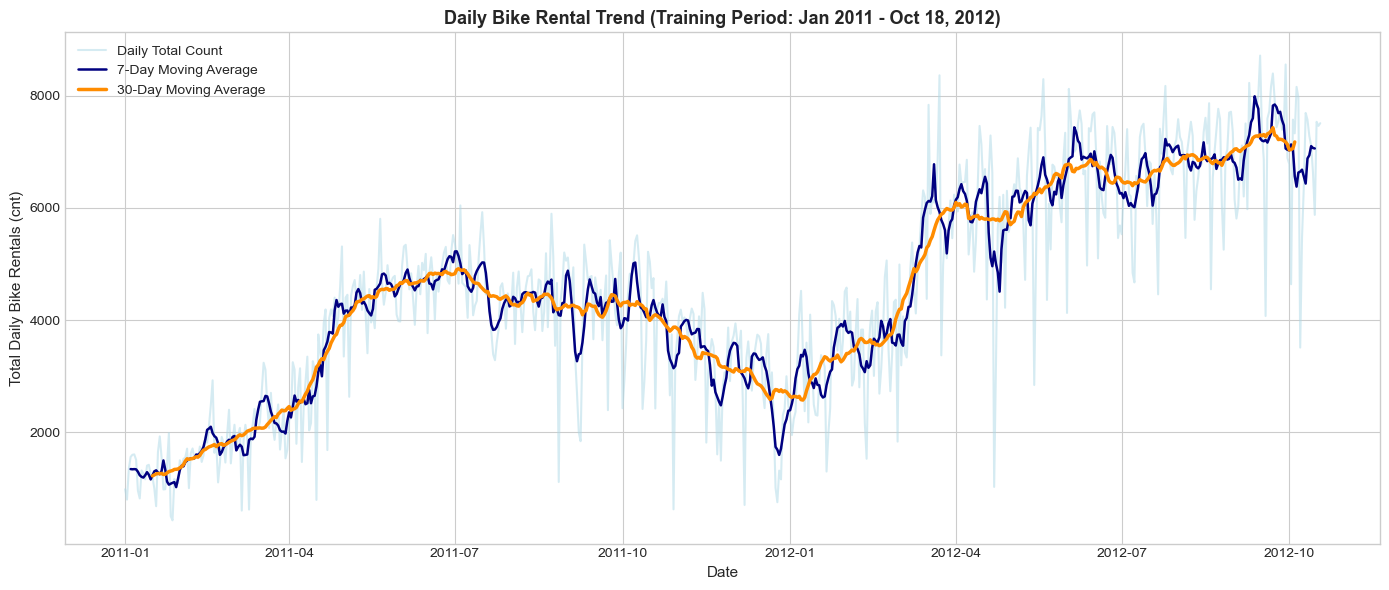

In [6]:
# Plot daily rental timeline over the training period
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_trend['dteday'], daily_trend['cnt'], color='lightblue', alpha=0.5, label='Daily Total Count')
ax.plot(daily_trend['dteday'], daily_trend['cnt_7d_mavg'], color='navy', linewidth=1.8, label='7-Day Moving Average')
ax.plot(daily_trend['dteday'], daily_trend['cnt_30d_mavg'], color='darkorange', linewidth=2.5, label='30-Day Moving Average')

ax.set_title('Daily Bike Rental Trend (Training Period: Jan 2011 - Oct 18, 2012)', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Total Daily Bike Rentals (cnt)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


### Interpretation:
**Author**: Lee Sin Yang

Overall trend is cyclical - peaking in the warmer seasons and declining in the colder. 2012 has a higher volume overall at around 6000-7000 in the warmer months, and appears to continue trending upwards up to the train set limit.

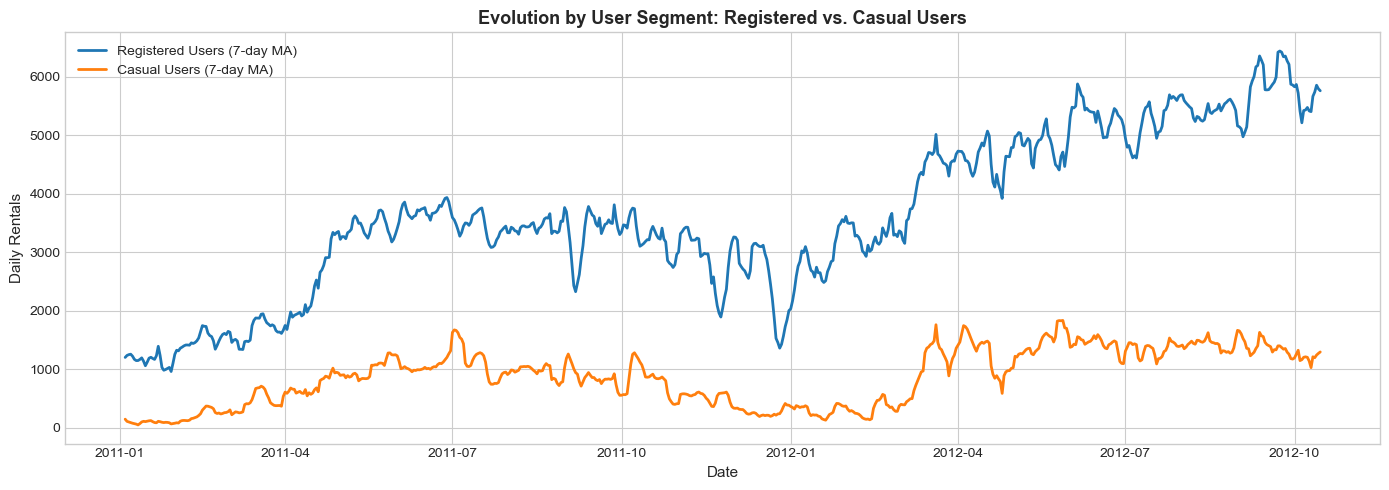

In [7]:
# Plot registered vs casual user evolution
daily_trend['cas_7d'] = daily_trend['casual'].rolling(7, center=True).mean()
daily_trend['reg_7d'] = daily_trend['registered'].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_trend['dteday'], daily_trend['reg_7d'], color='#1f77b4', linewidth=2, label='Registered Users (7-day MA)')
ax.plot(daily_trend['dteday'], daily_trend['cas_7d'], color='#ff7f0e', linewidth=2, label='Casual Users (7-day MA)')

ax.set_title('Evolution by User Segment: Registered vs. Casual Users', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Rentals')
ax.legend()
plt.tight_layout()
plt.show()


### Interpretation:
**Author**: Lee Sin Yang

The dataset has 2 kinds of users, registered and casual users. Registered users are the main demographic, but the growth year over year is from both users. Noticeable jumps are mainly in registered users, with a big spike around 2011 may and a big drop around 2012 january.

---
## 4. Question 2: What is the Overall Distribution of Bike Rentals? Does it Follow Any Statistical Distribution?
*Code: Generated by AI Assistant*


In [8]:
# Target distribution descriptive statistics on training data
cnt_train = train_df['cnt'].values
mean_cnt = np.mean(cnt_train)
var_cnt = np.var(cnt_train, ddof=1)
std_cnt = np.std(cnt_train, ddof=1)
median_cnt = np.median(cnt_train)
skew_cnt = stats.skew(cnt_train)
kurt_cnt = stats.kurtosis(cnt_train)
dispersion_index = var_cnt / mean_cnt

print(f"--- Training Target (cnt) Descriptive Statistics (N = {len(cnt_train):,}) ---")
print(f"Mean                  : {mean_cnt:.2f}")
print(f"Median                : {median_cnt:.2f}")
print(f"Variance              : {var_cnt:.2f}")
print(f"Standard Deviation    : {std_cnt:.2f}")
print(f"Skewness              : {skew_cnt:.3f}")
print(f"Kurtosis              : {kurt_cnt:.3f}")
print(f"Dispersion Index (Var/Mean): {dispersion_index:.2f}")


--- Training Target (cnt) Descriptive Statistics (N = 15,643) ---
Mean                  : 187.94
Median                : 140.00
Variance              : 32606.41
Standard Deviation    : 180.57
Skewness              : 1.298
Kurtosis              : 1.508
Dispersion Index (Var/Mean): 173.49


### Interpretation:
**Author**: Lee Sin Yang

Standard Deviation is high, at 180.57 vs the mean at 187.94. Mean is much higher than median (140), indicating the right tail as confirmed by the positive skew and excess kurtosis of 1.508.

In [9]:
# Parametric distribution fitting via Maximum Likelihood Estimation (MLE)
# 1. Normal
norm_stat, norm_p = stats.kstest(cnt_train, 'norm', args=(mean_cnt, std_cnt))
ll_norm = np.sum(stats.norm.logpdf(cnt_train, mean_cnt, std_cnt))

# 2. Gamma
shape_gam, loc_gam, scale_gam = stats.gamma.fit(cnt_train, floc=0)
gam_stat, gam_p = stats.kstest(cnt_train, 'gamma', args=(shape_gam, loc_gam, scale_gam))
ll_gam = np.sum(stats.gamma.logpdf(cnt_train, shape_gam, loc_gam, scale_gam))

# 3. Log-Normal
shape_ln, loc_ln, scale_ln = stats.lognorm.fit(cnt_train, floc=0)
ln_stat, ln_p = stats.kstest(cnt_train, 'lognorm', args=(shape_ln, loc_ln, scale_ln))
ll_ln = np.sum(stats.lognorm.logpdf(cnt_train, shape_ln, loc_ln, scale_ln))

# 4. Exponential
loc_exp, scale_exp = stats.expon.fit(cnt_train, floc=0)
exp_stat, exp_p = stats.kstest(cnt_train, 'expon', args=(loc_exp, scale_exp))
ll_exp = np.sum(stats.expon.logpdf(cnt_train, loc_exp, scale_exp))

# Goodness-of-fit comparison table
fit_comparison = pd.DataFrame({
    'Distribution': ['Gamma', 'Exponential', 'Log-Normal', 'Normal (Gaussian)'],
    'Parameters': [
        f"alpha={shape_gam:.3f}, scale={scale_gam:.1f}",
        f"scale={scale_exp:.1f}",
        f"sigma={shape_ln:.3f}, scale={scale_ln:.1f}",
        f"mu={mean_cnt:.1f}, sigma={std_cnt:.1f}"
    ],
    'Log-Likelihood': [ll_gam, ll_exp, ll_ln, ll_norm],
    'AIC': [2*2 - 2*ll_gam, 2*1 - 2*ll_exp, 2*2 - 2*ll_ln, 2*2 - 2*ll_norm],
    'KS-Statistic': [gam_stat, exp_stat, ln_stat, norm_stat],
    'KS p-value': [gam_p, exp_p, ln_p, norm_p]
}).sort_values('AIC')

fit_comparison


,Distribution,Parameters,Log-Likelihood,AIC,KS-Statistic,KS p-value
0,Gamma,"alpha=0.832, scale=225.8",-97366.621694,194737.243388,0.051298,3.242839e-36
1,Exponential,scale=187.9,-97551.687430,195105.374859,0.072629,3.344477e-72
2,Log-Normal,"sigma=1.488, scale=92.5",-99221.511632,198447.023264,0.116469,2.494247e-185
3,Normal (Gaussian),"mu=187.9, sigma=180.6",-103479.049862,206962.099724,0.150273,7.503531e-309


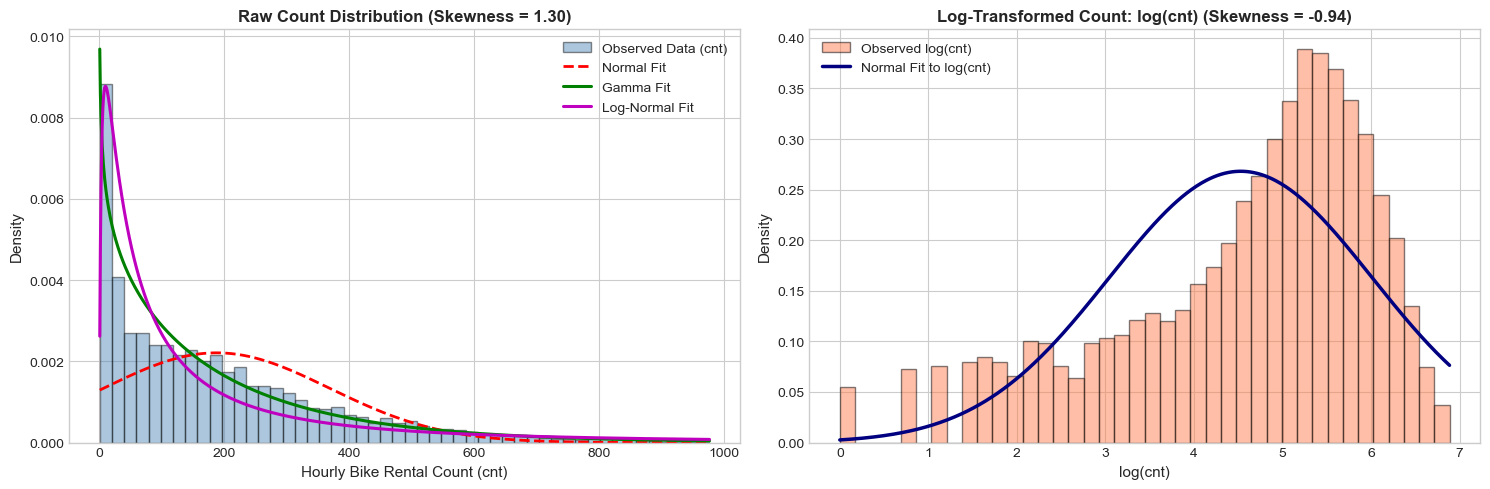

In [10]:
# Plot empirical density vs fitted curves and log-transformed count
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x_grid = np.linspace(1, cnt_train.max(), 1000)

# Raw count density
axes[0].hist(cnt_train, bins=50, density=True, alpha=0.45, color='steelblue', edgecolor='black', label='Observed Data (cnt)')
axes[0].plot(x_grid, stats.norm.pdf(x_grid, mean_cnt, std_cnt), 'r--', linewidth=2, label='Normal Fit')
axes[0].plot(x_grid, stats.gamma.pdf(x_grid, shape_gam, loc_gam, scale_gam), 'g-', linewidth=2.2, label='Gamma Fit')
axes[0].plot(x_grid, stats.lognorm.pdf(x_grid, shape_ln, loc_ln, scale_ln), 'm-', linewidth=2.2, label='Log-Normal Fit')
axes[0].set_title(f'Raw Count Distribution (Skewness = {skew_cnt:.2f})', fontweight='bold')
axes[0].set_xlabel('Hourly Bike Rental Count (cnt)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Log-transformed count density
log_cnt = np.log(cnt_train)
log_mean, log_std = np.mean(log_cnt), np.std(log_cnt, ddof=1)
log_skew, log_kurt = stats.skew(log_cnt), stats.kurtosis(log_cnt)

axes[1].hist(log_cnt, bins=40, density=True, alpha=0.5, color='coral', edgecolor='black', label='Observed log(cnt)')
x_log_grid = np.linspace(log_cnt.min(), log_cnt.max(), 500)
axes[1].plot(x_log_grid, stats.norm.pdf(x_log_grid, log_mean, log_std), 'navy', linewidth=2.5, 
             label=f'Normal Fit to log(cnt)')
axes[1].set_title(f'Log-Transformed Count: log(cnt) (Skewness = {log_skew:.2f})', fontweight='bold')
axes[1].set_xlabel('log(cnt)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()


### Interpretation:
**Author**: Lee Sin Yang

The data doesn't cleanly follow any of the selected distributions. All the KS tests were rejected, indicating a completely different distribution. We thus take a non parametric approach.

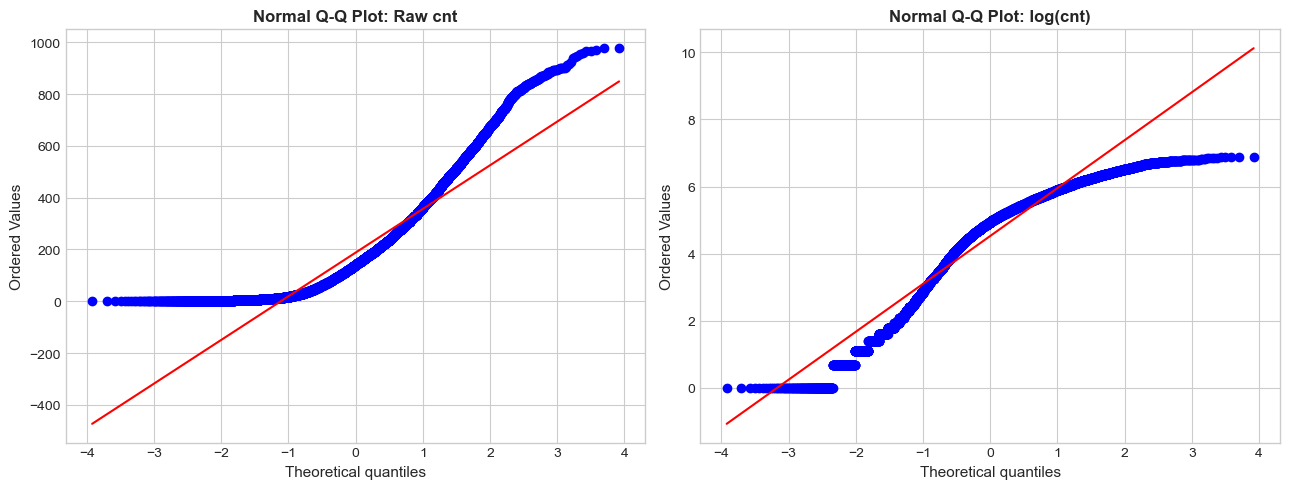

In [11]:
# Normal Q-Q Plots: raw count vs log(cnt)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stats.probplot(cnt_train, dist="norm", plot=axes[0])
axes[0].set_title('Normal Q-Q Plot: Raw cnt', fontweight='bold')

stats.probplot(log_cnt, dist="norm", plot=axes[1])
axes[1].set_title('Normal Q-Q Plot: log(cnt)', fontweight='bold')
plt.tight_layout()
plt.show()


### Interpretation & Modeling Decisions: Target Distribution
**Author**: Lee Sin Yang

The normal Q-Q plot is above the normal quantiles at the higher end, while also being higher at the lower end due to values being capped at zero. Taking a log of the count results in a slightly better fit, but the values at the higher end are now below the normal quantiles.


---
## 5. Question 3: How Do Different Time Aspects Affect Bike Rental?
*Code: Generated by AI Assistant*


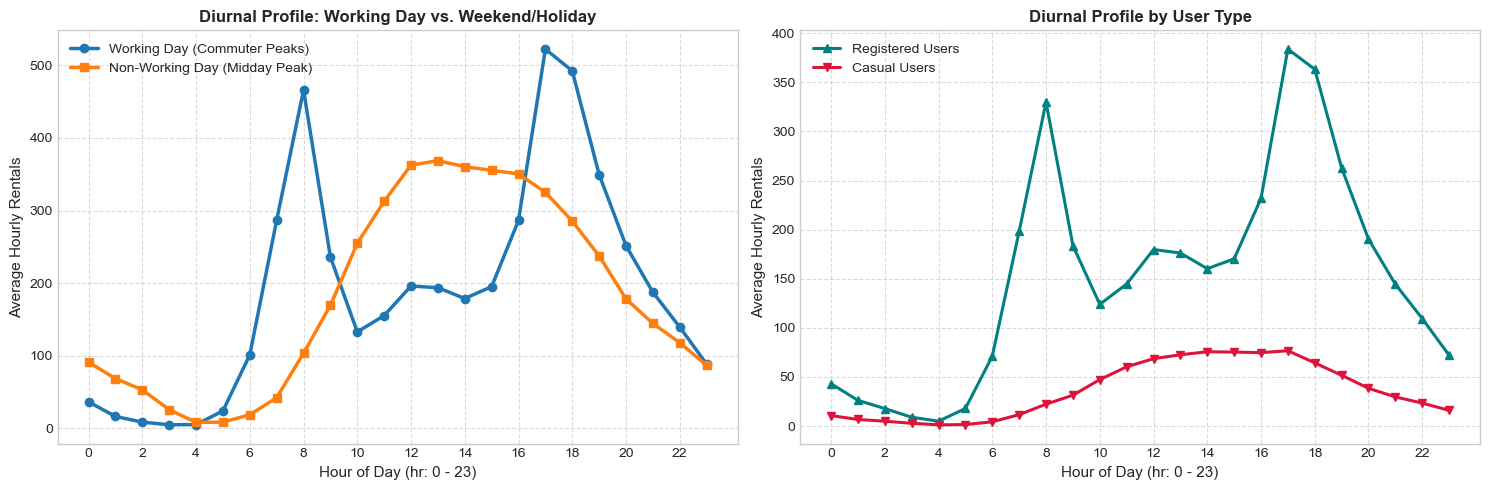

In [12]:
# Hourly diurnal profiles: working day vs weekend/holiday, and user segments
hr_working = train_df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()
hr_reg_cas = train_df.groupby('hr')[['registered', 'casual', 'cnt']].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Working vs non-working day
axes[0].plot(hr_working.index, hr_working[1], marker='o', linewidth=2.5, color='#1f77b4', 
             label='Working Day (Commuter Peaks)')
axes[0].plot(hr_working.index, hr_working[0], marker='s', linewidth=2.5, color='#ff7f0e', 
             label='Non-Working Day (Midday Peak)')
axes[0].set_title('Diurnal Profile: Working Day vs. Weekend/Holiday', fontweight='bold')
axes[0].set_xlabel('Hour of Day (hr: 0 - 23)')
axes[0].set_ylabel('Average Hourly Rentals')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# User segments across hours
axes[1].plot(hr_reg_cas.index, hr_reg_cas['registered'], marker='^', linewidth=2.2, color='teal', 
             label='Registered Users')
axes[1].plot(hr_reg_cas.index, hr_reg_cas['casual'], marker='v', linewidth=2.2, color='crimson', 
             label='Casual Users')
axes[1].set_title('Diurnal Profile by User Type', fontweight='bold')
axes[1].set_xlabel('Hour of Day (hr: 0 - 23)')
axes[1].set_ylabel('Average Hourly Rentals')
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


### Interpretation:
**Author**: Lee Sin Yang

On a working day, the peaks are at two main periods - between 6-10 am, a lull period from 10 to 4pm, and another spike at 4 to 9pm. On a non working day, the peak is one main one, picking up later at around 8am (2 hours later), peaking at around 12 to 4pm, and receding afterwards. The fall off is later into the night, with the non working day extending well into the early morning and falling below the working day finally at 4am. This different pattern is important when modelling - we will likely need a new feature for whether a day is a working day or non working day.

By hours of the day, the pattern can be seen similarly when splitting by registered and casual users. Registered users are likely the main bulk of working day renters, while casual users are usually on the weekends.

### Rush Hour Asymmetry on Working Days
*Code: Generated by AI Assistant*


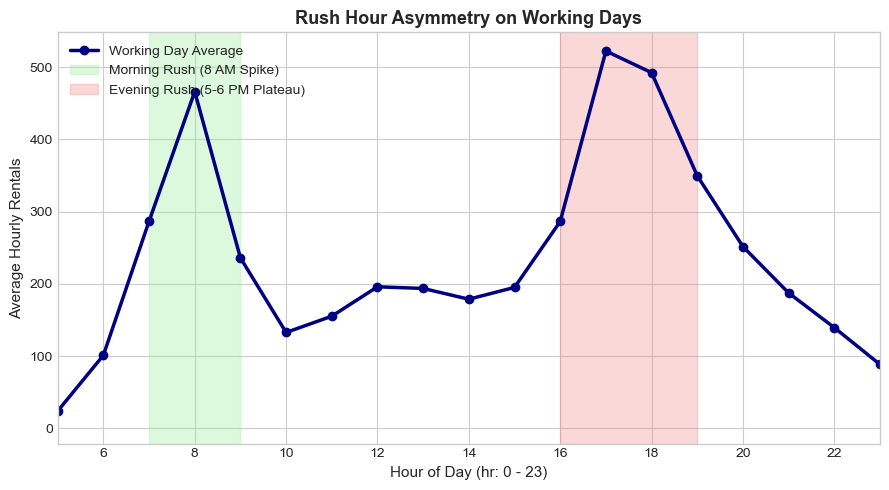

In [13]:
workday_hours = train_df[train_df['workingday'] == 1].groupby('hr')['cnt'].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(workday_hours.index, workday_hours.values, marker='o', color='navy', linewidth=2.5, label='Working Day Average')
ax.axvspan(7, 9, color='lightgreen', alpha=0.3, label='Morning Rush (8 AM Spike)')
ax.axvspan(16, 19, color='lightcoral', alpha=0.3, label='Evening Rush (5-6 PM Plateau)')
ax.set_title('Rush Hour Asymmetry on Working Days', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour of Day (hr: 0 - 23)')
ax.set_ylabel('Average Hourly Rentals')
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(5, 23)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


### Interpretation: Rush Hour Asymmetry
**Author**: Lee Sin Yang

The morning rush peaks more singularly at 8 and quickly falls off after to around 10am where it stagnates. The evening rush peak peaks around 2 hours of 5 and 6pm, with a more gradual falloff into the early morning.


### The Overnight "Dead Zone" (12:00 AM – 5:00 AM)
*Code: Generated by AI Assistant*


Overnight Hours (12 AM - 5 AM) Summary:
         mean  median  min  max
hr                             
0   53.710567    40.0    2  249
1   32.857362    20.0    1  168
2   22.695179    11.0    1  122
3   11.732484     6.0    1   66
4    6.202875     6.0    1   28
5   19.375194    18.0    1   66


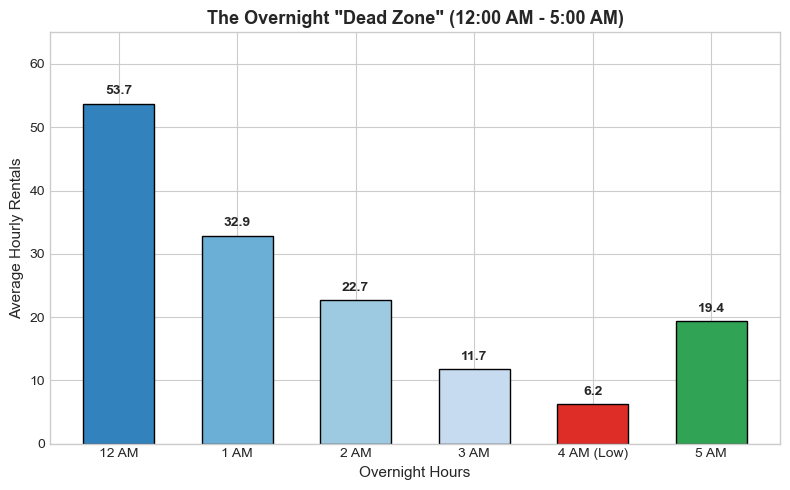

In [14]:
night_stats = train_df[train_df['hr'] <= 5].groupby('hr')['cnt'].agg(['mean', 'median', 'min', 'max'])
night_labels = ['12 AM', '1 AM', '2 AM', '3 AM', '4 AM (Low)', '5 AM']

print("Overnight Hours (12 AM - 5 AM) Summary:")
print(night_stats)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(night_labels, night_stats['mean'], color=['#3182bd', '#6baed6', '#9ecae1', '#c6dbef', '#de2d26', '#31a354'], edgecolor='black', width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}", ha='center', va='bottom', fontweight='bold')
ax.set_title('The Overnight "Dead Zone" (12:00 AM - 5:00 AM)', fontsize=13, fontweight='bold')
ax.set_xlabel('Overnight Hours')
ax.set_ylabel('Average Hourly Rentals')
ax.set_ylim(0, 65)
plt.tight_layout()
plt.show()

### Interpretation: Overnight Lows
**Author**: Lee Sin Yang
<!-- Add your written interpretation of overnight baseline demand and minimum values here -->


Holiday Mean: 160.2 vs Non-Holiday Mean: 188.7 (p = 0.0002)
Workingday Mean: 191.0 vs Non-Workingday Mean: 181.2 (p = 0.0012)


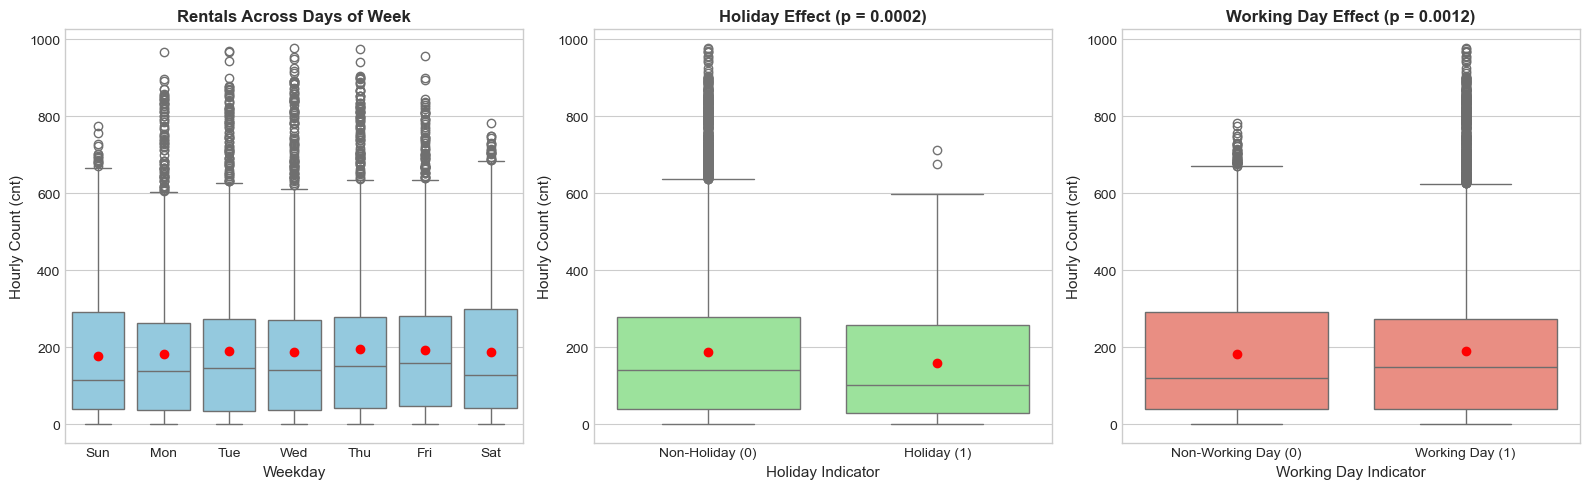

In [15]:
# Weekday, holiday, and working day comparisons
cnt_hol = train_df[train_df['holiday'] == 1]['cnt']
cnt_nonhol = train_df[train_df['holiday'] == 0]['cnt']
ttest_hol = stats.ttest_ind(cnt_hol, cnt_nonhol, equal_var=False)

cnt_work = train_df[train_df['workingday'] == 1]['cnt']
cnt_nonwork = train_df[train_df['workingday'] == 0]['cnt']
ttest_work = stats.ttest_ind(cnt_work, cnt_nonwork, equal_var=False)

print(f"Holiday Mean: {cnt_hol.mean():.1f} vs Non-Holiday Mean: {cnt_nonhol.mean():.1f} (p = {ttest_hol.pvalue:.4f})")
print(f"Workingday Mean: {cnt_work.mean():.1f} vs Non-Workingday Mean: {cnt_nonwork.mean():.1f} (p = {ttest_work.pvalue:.4f})")

weekday_labels = ['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x='weekday', y='cnt', data=train_df, ax=axes[0], color='skyblue', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red'))
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(weekday_labels)
axes[0].set_title('Rentals Across Days of Week', fontweight='bold')
axes[0].set_xlabel('Weekday')
axes[0].set_ylabel('Hourly Count (cnt)')

sns.boxplot(x='holiday', y='cnt', data=train_df, ax=axes[1], color='lightgreen', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red'))
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Non-Holiday (0)', 'Holiday (1)'])
axes[1].set_title(f'Holiday Effect (p = {ttest_hol.pvalue:.4f})', fontweight='bold')
axes[1].set_xlabel('Holiday Indicator')
axes[1].set_ylabel('Hourly Count (cnt)')

sns.boxplot(x='workingday', y='cnt', data=train_df, ax=axes[2], color='salmon', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red'))
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Non-Working Day (0)', 'Working Day (1)'])
axes[2].set_title(f'Working Day Effect (p = {ttest_work.pvalue:.4f})', fontweight='bold')
axes[2].set_xlabel('Working Day Indicator')
axes[2].set_ylabel('Hourly Count (cnt)')

plt.tight_layout()
plt.show()


### Interpretation:
**Author**: Lee Sin Yang

Within the days of the week, the means are fairly similar but the IQR of saturday and sunday are larger. The overall range of the weekdays is higher but are labelled outliers. 

Holidays have lower means and rangers than the non holidays (p = 0.0002)

Working days have higher means and ranges than non working days, but non working days have a higher IQR. This is consistent with our previous findings on high peaks on workdays compared to a longer but lower peak.

In [16]:
# Month vs Season cross-tabulation and Variance Inflation Factor (VIF)
season_month_ct = pd.crosstab(train_df['mnth'], train_df['season'])
print("Cross-Tabulation of Month (mnth) vs Season (season):")
print(season_month_ct)

# VIF diagnostic
vif_features = ['season', 'mnth', 'temp', 'atemp', 'hum', 'windspeed']
X_vif = train_df[vif_features].dropna()
vif_df = pd.DataFrame({
    'Feature': vif_features,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(len(vif_features))]
}).sort_values('VIF', ascending=False)

print("\nVariance Inflation Factors (VIF):")
vif_df


Cross-Tabulation of Month (mnth) vs Season (season):
season     1     2     3     4
mnth                          
1       1429     0     0     0
2       1341     0     0     0
3        949   524     0     0
4          0  1437     0     0
5          0  1488     0     0
6          0   960   480     0
7          0     0  1488     0
8          0     0  1475     0
9          0     0  1053   384
10         0     0     0  1175
11         0     0     0   719
12       261     0     0   480

Variance Inflation Factors (VIF):


,Feature,VIF
3,atemp,342.722020
2,temp,317.847895
0,season,26.775773
1,mnth,18.904784
4,hum,6.822921
5,windspeed,2.741027


### Interpretation:
**Author**: Lee Sin Yang

Season is deterministic based on the date. VIF for atemp, temp, season, mnth are high and should be investigated. VIF for hum and windspeed are still moderate but not as high as the others (<10)

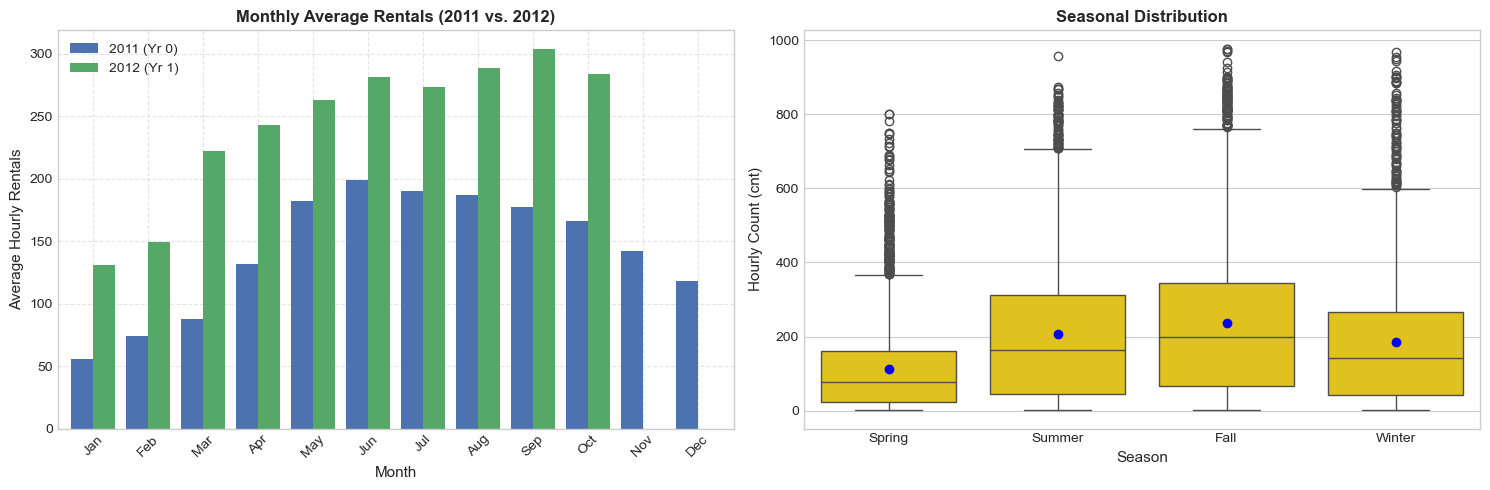

In [17]:
# Monthly and seasonal distribution plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
mnth_yr = train_df.groupby(['mnth', 'yr'])['cnt'].mean().unstack()

mnth_yr.plot(kind='bar', ax=axes[0], color=['#4c72b0', '#55a868'], width=0.8)
axes[0].set_title('Monthly Average Rentals (2011 vs. 2012)', fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Average Hourly Rentals')
axes[0].set_xticks(range(len(mnth_yr)))
axes[0].set_xticklabels([month_names[i-1] for i in mnth_yr.index], rotation=45)
axes[0].legend(['2011 (Yr 0)', '2012 (Yr 1)'])
axes[0].grid(True, linestyle='--', alpha=0.5)

season_names = ['Spring', 'Summer', 'Fall', 'Winter']
sns.boxplot(x='season', y='cnt', data=train_df, ax=axes[1], color='gold', showmeans=True,
            meanprops=dict(marker='o', markerfacecolor='blue', markeredgecolor='blue'))
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(season_names)
axes[1].set_title('Seasonal Distribution', fontweight='bold')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Hourly Count (cnt)')

plt.tight_layout()
plt.show()


### Interpretation & Modeling Decisions: Time Aspects & Multicollinearity
**Author**: Lee Sin Yang 

The year over year trend can be seen here, also the peak month has shifted from June in 2011 to September in 2012. The seasonal distribution is higher in the warmer seasons as previously identified.


---
## 6. Question 4: How Do Weather Conditions Affect Bike Rental?

### 6.1 Weather Severity Breakdown (`weathersit`)
*Code: Generated by AI Assistant*


Weather Severity Summary Table:
            count  pct_of_rows        mean  pct_drop_vs_clear
weathersit                                                   
1           10443    66.758294  203.394714           0.000000
2            3896    24.905709  171.782084          15.542503
3            1301     8.316819  112.538048          44.670122
4               3     0.019178   74.333333          63.453655


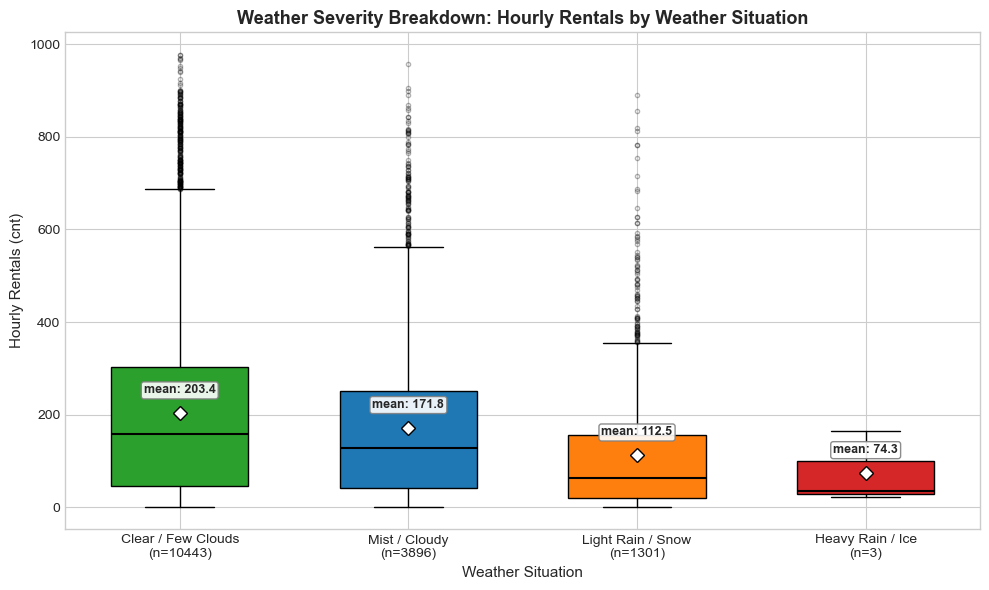

In [18]:
weather_labels = {1: 'Clear / Few Clouds', 2: 'Mist / Cloudy',
                  3: 'Light Rain / Snow', 4: 'Heavy Rain / Ice'}
weather_colors = {1: '#2ca02c', 2: '#1f77b4', 3: '#ff7f0e', 4: '#d62728'}

w_stats = train_df.groupby('weathersit')['cnt'].agg(['count', 'mean', 'median', 'std'])
w_stats['pct_of_rows'] = w_stats['count'] / len(train_df) * 100
w_stats['pct_drop_vs_clear'] = (w_stats.loc[1, 'mean'] - w_stats['mean']) / w_stats.loc[1, 'mean'] * 100

print("Weather Severity Summary Table:")
print(w_stats[['count', 'pct_of_rows', 'mean', 'pct_drop_vs_clear']])

levels = list(w_stats.index)  # only plot categories present in the training set
data = [train_df.loc[train_df['weathersit'] == w, 'cnt'].dropna() for w in levels]
tick_labels = [f"{weather_labels[w]}\n(n={len(d)})" for w, d in zip(levels, data)]

fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot(
    data,
    tick_labels=tick_labels,      # use labels= on matplotlib < 3.9
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7),
    medianprops=dict(color='black', linewidth=1.5),
    flierprops=dict(marker='o', markersize=3, alpha=0.3),
)
for patch, w in zip(bp['boxes'], levels):
    patch.set_facecolor(weather_colors[w])
    patch.set_edgecolor('black')

# Label the mean on each box
for i, d in enumerate(data, start=1):
    if len(d) == 0:
        continue
    m = d.mean()
    ax.annotate(f"mean: {m:.1f}", xy=(i, m), xytext=(0, 12), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.9))

ax.set_title('Weather Severity Breakdown: Hourly Rentals by Weather Situation',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Weather Situation')
ax.set_ylabel('Hourly Rentals (cnt)')
plt.tight_layout()
plt.show()

### Interpretation: Weather Severity Breakdown
**Author**: Lee Sin Yang
Weather highly impacts the number of rentals in an hour, with 203.4 on a clear day on average per hour and only 74.3 in heavy rain / ice. Most hours are clear (10443), with only 3 in heavy rain / ice.


### 6.2 Temperature Comfort Zones
*Code: Generated by AI Assistant*


count    15643.000000
mean        21.014865
std          7.949267
min          0.820000
25%         14.760000
50%         22.140000
75%         27.060000
max         41.000000
Name: temp_c, dtype: float64
temp_c
Cold (<10°C)      1768
Cool (10-20°C)    5059
Warm (20-30°C)    6703
Hot (30°C+)       2113
Name: count, dtype: int64
Temperature Comfort Zones Summary:
                count        mean  median
temp_bin                                 
Cold (<10°C)     1768   67.929299    44.0
Cool (10-20°C)   5059  130.527575    94.0
Warm (20-30°C)   6703  218.699090   178.0
Hot (30°C+)      2113  328.239943   292.0


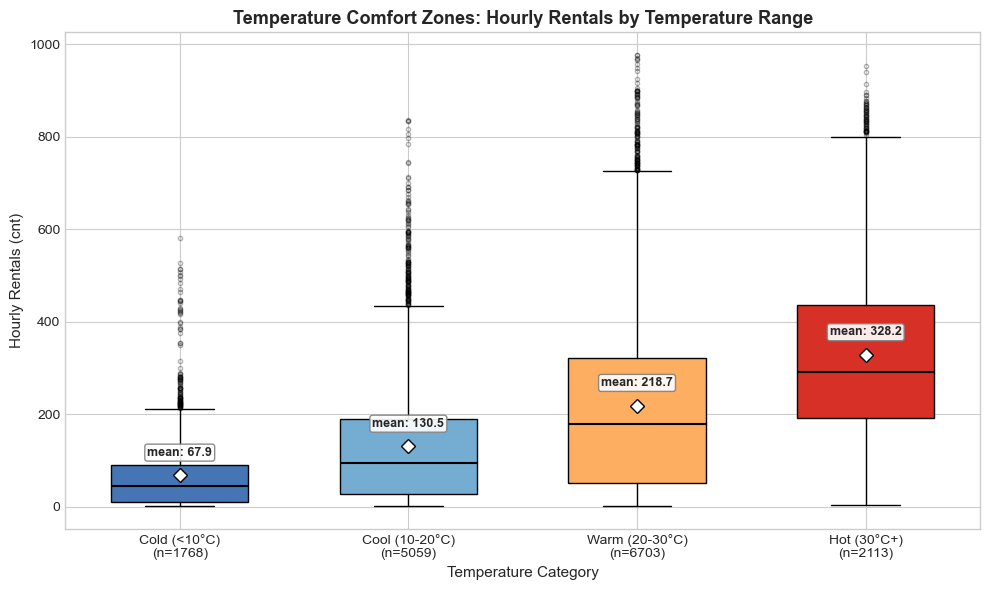

In [19]:
bins_temp = [-10, 10, 20, 30, 50]
labels_temp = ['Cold (<10°C)', 'Cool (10-20°C)', 'Warm (20-30°C)', 'Hot (30°C+)']
colors = ['#4575b4', '#74add1', '#fdae61', '#d73027']

# Quick check of the distribution before settling on bands
print(train_df['temp_c'].describe())
print(pd.cut(train_df['temp_c'], bins=bins_temp, labels=labels_temp).value_counts().sort_index())

train_df['temp_bin'] = pd.cut(train_df['temp_c'], bins=bins_temp, labels=labels_temp)
t_stats = train_df.groupby('temp_bin', observed=False)['cnt'].agg(['count', 'mean', 'median'])

print("Temperature Comfort Zones Summary:")
print(t_stats)

data = [train_df.loc[train_df['temp_bin'] == lab, 'cnt'].dropna() for lab in labels_temp]
tick_labels = [f"{lab}\n(n={len(d)})" for lab, d in zip(labels_temp, data)]

fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot(
    data,
    tick_labels=tick_labels,      # use labels= on matplotlib < 3.9
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7),
    medianprops=dict(color='black', linewidth=1.5),
    flierprops=dict(marker='o', markersize=3, alpha=0.3),
)
for patch, c in zip(bp['boxes'], colors):
    patch.set_facecolor(c)
    patch.set_edgecolor('black')

# Label the mean on each box
for i, d in enumerate(data, start=1):
    if len(d) == 0:
        continue
    m = d.mean()
    ax.annotate(f"mean: {m:.1f}", xy=(i, m), xytext=(0, 12), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.9))

ax.set_title('Temperature Comfort Zones: Hourly Rentals by Temperature Range',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Temperature Category')
ax.set_ylabel('Hourly Rentals (cnt)')
plt.tight_layout()
plt.show()

### Interpretation: Temperature Comfort Zones
**Author**: Lee Sin Yang
Similarly with temperature. Only 67.9 bikes are rented on average per hour in the cold, while 328.2 on average in the hot.


### 6.3 Humidity & Mugginess Bands
*Code: Generated by AI Assistant*


Humidity Bands Summary:
                      count        mean  median
hum_bin                                        
Dry (<40%)             2330  282.781545   239.5
Comfortable (40-65%)   6132  214.443412   178.0
Humid (65-80%)         3623  164.963014   114.0
Muggy (>80%)           3558  103.552558    56.0


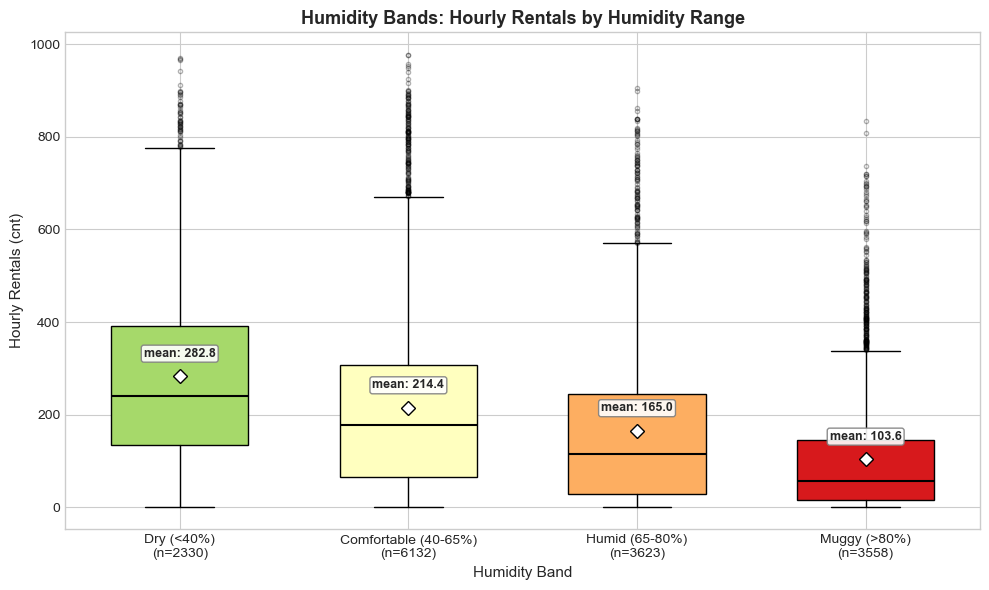

In [20]:
bins_hum = [-0.01, 40, 65, 80, 100]
labels_hum = ['Dry (<40%)', 'Comfortable (40-65%)', 'Humid (65-80%)', 'Muggy (>80%)']
colors = ['#a6d96a', '#ffffbf', '#fdae61', '#d7191c']

train_df['hum_bin'] = pd.cut(train_df['hum_pct'], bins=bins_hum, labels=labels_hum)
h_stats = train_df.groupby('hum_bin', observed=False)['cnt'].agg(['count', 'mean', 'median'])

print("Humidity Bands Summary:")
print(h_stats)

data = [train_df.loc[train_df['hum_bin'] == lab, 'cnt'].dropna() for lab in labels_hum]
tick_labels = [f"{lab}\n(n={len(d)})" for lab, d in zip(labels_hum, data)]

fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot(
    data,
    tick_labels=tick_labels,      # use labels= on matplotlib < 3.9
    patch_artist=True,
    widths=0.6,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7),
    medianprops=dict(color='black', linewidth=1.5),
    flierprops=dict(marker='o', markersize=3, alpha=0.3),
)
for patch, c in zip(bp['boxes'], colors):
    patch.set_facecolor(c)
    patch.set_edgecolor('black')

# Label the mean on each box
for i, d in enumerate(data, start=1):
    if len(d) == 0:
        continue
    m = d.mean()
    ax.annotate(f"mean: {m:.1f}", xy=(i, m), xytext=(0, 12), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.9))

ax.set_title('Humidity Bands: Hourly Rentals by Humidity Range',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Humidity Band')
ax.set_ylabel('Hourly Rentals (cnt)')
plt.tight_layout()
plt.show()

### Interpretation: Humidity Bands
**Author**: Lee Sin Yang
As humidity increases, the hourly rental decreases. It goes from mean 282.8 in dry weather to mean 103.6 in muggy weather. This could also be autocorrelated to weather.


### 6.4 Commuters vs. Casual Riders in Adverse Weather
*Code: Generated by AI Assistant*


Clear Weather Means  : Registered = 162.2, Casual = 41.2
Rain/Snow Means      : Registered = 95.9, Casual = 16.7
Percentage Drop in Rain: Registered = -40.9%, Casual = -59.5%


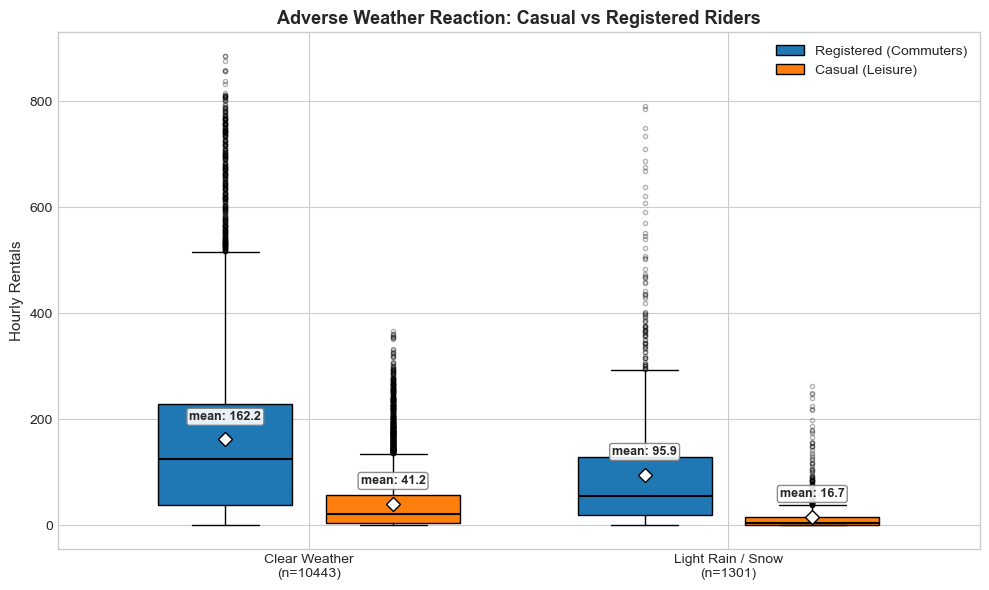

In [21]:
import matplotlib.patches as mpatches

w_sel = [1, 3]
w_names = ['Clear Weather', 'Light Rain / Snow']
series = [('registered', 'Registered (Commuters)', '#1f77b4'),
          ('casual', 'Casual (Leisure)', '#ff7f0e')]

# Summary stats (same as before)
w_user = train_df.groupby('weathersit')[['casual', 'registered', 'cnt']].mean()
reg_drop = (w_user.loc[1, 'registered'] - w_user.loc[3, 'registered']) / w_user.loc[1, 'registered'] * 100
cas_drop = (w_user.loc[1, 'casual'] - w_user.loc[3, 'casual']) / w_user.loc[1, 'casual'] * 100
print(f"Clear Weather Means  : Registered = {w_user.loc[1, 'registered']:.1f}, Casual = {w_user.loc[1, 'casual']:.1f}")
print(f"Rain/Snow Means      : Registered = {w_user.loc[3, 'registered']:.1f}, Casual = {w_user.loc[3, 'casual']:.1f}")
print(f"Percentage Drop in Rain: Registered = -{reg_drop:.1f}%, Casual = -{cas_drop:.1f}%")

fig, ax = plt.subplots(figsize=(10, 6))
offset, width = 0.2, 0.32

for j, (col, _, color) in enumerate(series):
    pos_shift = -offset if j == 0 else offset
    data = [train_df.loc[train_df['weathersit'] == w, col].dropna() for w in w_sel]
    positions = [i + 1 + pos_shift for i in range(len(w_sel))]
    bp = ax.boxplot(
        data, positions=positions, widths=width, patch_artist=True,
        showmeans=True,
        meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=7),
        medianprops=dict(color='black', linewidth=1.5),
        flierprops=dict(marker='o', markersize=3, alpha=0.3),
    )
    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_edgecolor('black')
    # Mean labels
    for pos, d in zip(positions, data):
        if len(d) == 0:
            continue
        m = d.mean()
        ax.annotate(f"mean: {m:.1f}", xy=(pos, m), xytext=(0, 12), textcoords='offset points',
                    ha='center', va='bottom', fontweight='bold', fontsize=9,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='gray', alpha=0.9))

counts = [(train_df['weathersit'] == w).sum() for w in w_sel]
ax.set_xticks([1, 2])
ax.set_xticklabels([f"{n}\n(n={c})" for n, c in zip(w_names, counts)])
ax.set_xlim(0.4, 2.6)
ax.set_title('Adverse Weather Reaction: Casual vs Registered Riders', fontsize=13, fontweight='bold')
ax.set_ylabel('Hourly Rentals')
ax.legend(handles=[mpatches.Patch(facecolor=c, edgecolor='black', label=l) for _, l, c in series])
plt.tight_layout()
plt.show()

### Interpretation: Commuter vs. Casual Weather Elasticity
**Author**: Lee Sin Yang

Demand for registered users is more inelastic than casual users, as these are likely users with jobs using bike rentals as their main form of commuting.


---
## 7. Question 5: Are There Any Outliers? How Should They Be Adjudicated?
*Code: Generated by AI Assistant*


In [22]:
# Hourly level outlier screening via Tukey's IQR rule
q1 = train_df['cnt'].quantile(0.25)
q3 = train_df['cnt'].quantile(0.75)
iqr = q3 - q1
upper_whisker = q3 + 1.5 * iqr

hourly_outliers = train_df[train_df['cnt'] > upper_whisker]
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
print(f"Upper Cutoff (Q3 + 1.5*IQR): {upper_whisker:.1f}")
print(f"Flagged hourly observations: {len(hourly_outliers):,} ({len(hourly_outliers)/len(train_df)*100:.2f}% of training set)")
print("\nHours with highest frequency of flagged outliers:")
print(hourly_outliers['hr'].value_counts().head(5))


Q1 = 40.0, Q3 = 279.0, IQR = 239.0
Upper Cutoff (Q3 + 1.5*IQR): 637.5
Flagged hourly observations: 462 (2.95% of training set)

Hours with highest frequency of flagged outliers:
hr
17    143
18    127
8     103
13     20
12     16
Name: count, dtype: int64


### Interpretation:
**Author**: Lee Sin Yang

Most of the hours (270) with many outliers are in the late day (17-18), with 103 others in the morning (8). This fits with the two peaks of the workdays.

In [23]:
# Daily aggregate outlier screening and event cross-referencing
daily_summary = train_df.groupby(['dteday', 'yr', 'mnth']).agg({
    'cnt': 'sum',
    'weathersit': 'mean',
    'temp_c': 'mean',
    'windspeed_kmh': 'mean',
    'hum_pct': 'mean'
}).reset_index()

# 10 lowest daily totals across training period
lowest_days = daily_summary.sort_values('cnt').head(10)
print("10 Lowest Demand Days:")
lowest_days[['dteday', 'cnt', 'weathersit', 'temp_c', 'windspeed_kmh']]


10 Lowest Demand Days:


,dteday,cnt,weathersit,temp_c,windspeed_kmh
26,2011-01-27,431,1.000000,7.995000,7.627112
25,2011-01-26,506,2.937500,8.917500,19.687950
64,2011-03-06,605,2.391304,15.437391,23.000226
68,2011-03-10,623,2.909091,15.952727,17.545777
301,2011-10-29,627,2.583333,10.420833,23.541846
17,2011-01-18,683,2.000000,8.883333,9.833925
340,2011-12-07,705,2.791667,16.810000,17.833725
358,2011-12-25,754,1.000000,11.266087,10.391117
105,2011-04-16,795,2.500000,17.664167,22.834158
1,2011-01-02,801,1.956522,14.902609,16.652122


### Interpretation:
**Author**: Kok Wai Ying 

Of the 10 days with the lowest demand, all are in 2011. The far and away lowest demand day with 431 total rentals is on 27 Janaury 2011. It can be determined that the count of ridership generally decrease with a decrease in temp_c. We see ridership at the lowest of 431 cnt while temp_c is the lowest at 7.995 and ridership is the highest at 801 when temp_c is around 14.90. 

In [24]:
# 10 highest daily totals across training period
highest_days = daily_summary.sort_values('cnt', ascending=False).head(10)
print("10 Highest Demand Days:")
highest_days[['dteday', 'cnt', 'weathersit', 'temp_c', 'windspeed_kmh']]


10 Highest Demand Days:


,dteday,cnt,weathersit,temp_c,windspeed_kmh
623,2012-09-15,8714,1.208333,24.941667,16.583896
637,2012-09-29,8555,1.083333,22.242500,15.249479
630,2012-09-22,8395,1.000000,26.650000,19.000083
447,2012-03-23,8362,1.583333,24.668333,7.792100
504,2012-05-19,8294,1.000000,24.600000,5.626325
617,2012-09-09,8227,1.041667,25.010000,15.041221
571,2012-07-25,8173,1.000000,29.690833,11.041600
629,2012-09-21,8167,1.000000,24.565833,10.333354
643,2012-10-05,8156,1.000000,25.215000,7.125450
518,2012-06-02,8120,1.166667,23.916667,12.499688


### Interpretation:
**Author**: Lee Sin Yang

Of the highest demand days, all are from 2012 (consistent with the year on year growth). temperature is in the mid to high 20s, with wind speed under 20kmh.

In [ ]:
# Distribution plots for hourly and daily scale outliers
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x='hr', y='cnt', data=train_df, ax=axes[0], color='lightsteelblue',
            flierprops=dict(marker='o', markersize=2, alpha=0.3))
axes[0].set_title('Hourly Rental Boxplots and Outliers', fontweight='bold')
axes[0].set_xlabel('Hour of Day (hr)')
axes[0].set_ylabel('Hourly Count (cnt)')

axes[1].hist(daily_summary['cnt'], bins=35, color='teal', edgecolor='black', alpha=0.7)
p1 = daily_summary['cnt'].quantile(0.01)
p99 = daily_summary['cnt'].quantile(0.99)
axes[1].axvline(p1, color='red', linestyle='--', linewidth=2, label=f'1st Percentile ({p1:.0f})')
axes[1].axvline(p99, color='green', linestyle='--', linewidth=2, label=f'99th Percentile ({p99:.0f})')
axes[1].set_title('Daily Aggregate Count Distribution', fontweight='bold')
axes[1].set_xlabel('Daily Total Rentals')
axes[1].set_ylabel('Number of Days')
axes[1].legend()

plt.tight_layout()
plt.show()


### Interpretation & Adjudication Decisions: Outliers & Events
**Author**: Lee Sin Yang
  
Based on the boxplot, the outliers on an hourly basis are largely in the early mornings between 12 to 4am and in the midday during 10 to 5pm. This could be attributed to the different peaks of a weekday and weekend, which have different distributions.


---
## 8. Question 6: Scatter Plots of How Different Variables Interact with Count
*Code: Generated by AI Assistant*


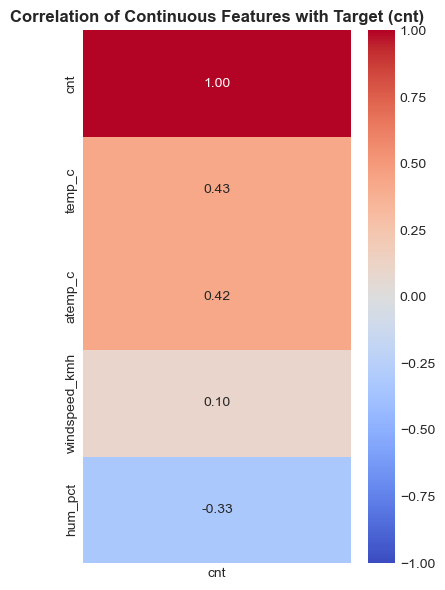

In [26]:
# Correlation matrix among continuous predictors and target 'cnt'
cols_to_corr = ['temp_c', 'atemp_c', 'hum_pct', 'windspeed_kmh', 'cnt']
corr_matrix = train_df[cols_to_corr].corr()

# Plot only the 'cnt' column as a heatmap
plt.figure(figsize=(4, 6))
sns.heatmap(corr_matrix[['cnt']].sort_values(by='cnt', ascending=False), 
            annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')

plt.title('Correlation of Continuous Features with Target (cnt)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation
**Author**: Kok Wai Ying 

1. hum_pct has a moderate negative linear relationship with cnt at r = -0.33
2. windspeed_kmh has a weak/no linear relationship with cnt at  r= 0.10
3. atemp_c and temp_c has a moderate positive linear relationship with cnt at r= 0.42 and  r= 0.43 respectively 

In [ ]:
# Scatter plots of continuous predictors against count with order-2 trendlines
sample_train = train_df.sample(3000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

# Temperature
sns.regplot(x='temp_c', y='cnt', data=sample_train, ax=axes[0], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'coral', 's': 12},
            line_kws={'color': 'red', 'linewidth': 2.5})
axes[0].set_title(f"Temperature vs. Count (r = {train_df['temp_c'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[0].set_xlabel('Temperature (°C)')
axes[0].set_ylabel('Hourly Count (cnt)')

# Feeling Temperature
sns.regplot(x='atemp_c', y='cnt', data=sample_train, ax=axes[1], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'darkorange', 's': 12},
            line_kws={'color': 'brown', 'linewidth': 2.5})
axes[1].set_title(f"Feeling Temperature vs. Count (r = {train_df['atemp_c'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[1].set_xlabel('Feeling Temperature (°C)')
axes[1].set_ylabel('Hourly Count (cnt)')

# Humidity
sns.regplot(x='hum_pct', y='cnt', data=sample_train, ax=axes[2], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'teal', 's': 12},
            line_kws={'color': 'darkblue', 'linewidth': 2.5})
axes[2].set_title(f"Humidity vs. Count (r = {train_df['hum_pct'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[2].set_xlabel('Humidity (%)')
axes[2].set_ylabel('Hourly Count (cnt)')

# Windspeed
sns.regplot(x='windspeed_kmh', y='cnt', data=sample_train, ax=axes[3], order=2,
            scatter_kws={'alpha': 0.18, 'color': 'purple', 's': 12},
            line_kws={'color': 'indigo', 'linewidth': 2.5})
axes[3].set_title(f"Wind Speed vs. Count (r = {train_df['windspeed_kmh'].corr(train_df['cnt']):.2f})", fontweight='bold')
axes[3].set_xlabel('Wind Speed (km/h)')
axes[3].set_ylabel('Hourly Count (cnt)')

plt.tight_layout()
plt.show()


### Interpretation
**Author**: Lee Sin Yang

The scatter plots reinforce the correlation metrics, albeit it does show that for wind speed there is a nonlinear relationship happening. The ideal wind speed is around 20 kmh, with decreases lower and higher than that (with also much less data points)

In [ ]:
# Interaction plots: Hour x Weekday and Temperature x Season
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Heatmap: Hour x Weekday
hr_wday_pivot = train_df.pivot_table(index='hr', columns='weekday', values='cnt', aggfunc='mean')
hr_wday_pivot.columns = weekday_labels
sns.heatmap(hr_wday_pivot, cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Mean Hourly Rentals'})
axes[0].set_title('Interaction Heatmap: Hour × Day of Week', fontweight='bold')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Hour of Day (hr)')

# Scatter: Temperature vs Count by Season
sns.scatterplot(x='temp_c', y='cnt', hue='season', data=sample_train,
                palette='tab10', alpha=0.55, ax=axes[1])
axes[1].set_title('Interaction: Temperature vs. Count Stratified by Season', fontweight='bold')
axes[1].set_xlabel('Temperature (°C)')
axes[1].set_ylabel('Hourly Count (cnt)')
axes[1].legend(title='Season', labels=season_names)

plt.tight_layout()
plt.show()


In [ ]:
# Correlation heatmap of all numeric variables in training set
plt.figure(figsize=(11, 9))
feature_cols = ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit',
                'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
sns.heatmap(train_df[feature_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar=True)
plt.title('Correlation Heatmap: Training Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Interpretation & Modeling Decisions: Nonlinearity & Interactions
**Author**: Lee Sin Yang 
Correlation between certain variables is expected. This chart should thus not be inferred too deeply.


---
## 9. Modeling Synthesis & Decision Blueprint
**Author**: [Insert Name]

<!-- Use this section to record your team's modeling decisions, feature engineering plans, transformation strategies, and regularized regression choices based on the EDA findings above. -->

| Aspect | EDA Observation | Team Modeling Decision | Rationale |
| :--- | :--- | :--- | :--- |
| **Train/Test Split** | | | |
| **Hour (`hr`) Encoding** | | | |
| **Month vs. Season** | | | |
| **Temperature (`temp`, `atemp`)** | | | |
| **Target Transformation ($\log(cnt)$)** | | | |
| **Outlier Handling** | | | |
| **Regularization Strategy** | | | |

---
*End of Notebook 01 EDA.*
